# 첫인상 리포트: 피드 캡처로 첫인상 키워드와 개선안 만들기
순천향대학교 AI빅데이터학과 이소미 · LLM 수업 프로젝트

피드 캡처 9장과 소개글을 넣으면, 처음 본 사람이 받을 첫인상 키워드 5개와 근거 사진, 개선안 3개(대표 이미지·색감·소개글)를 만든다. 외모는 평가하지 않는다.

| 단계 | 하는 일 | 수업 | 모델 |
|---|---|---|---|
| [0] 전처리 | 그리드 캡처 → 사진 9장, EXIF 제거 | - | PIL |
| [A] 색감 통계 | 팔레트·밝기·채도·통일감 | - | scikit-learn KMeans |
| [B] 인상 키워드 | 키워드 30개·주제 12개 제로샷 점수 | 9장 | CLIP ViT-B/32 |
| [C] 사진 캡션 | 사진마다 영어 캡션 1줄 | 9장 | BLIP-2 OPT-2.7B (8bit) |
| [D] 소개글 톤 | 임베딩 제로샷 분류 | 4장 | bge-m3 (CPU) |
| [E] 가이드 카드 검색 | BM25 + 벡터 하이브리드, RRF | 8장 | bge-m3 + rank_bm25 |
| [F] 리포트 생성 | ICL 예시 2개 + JSON 출력 | 6장 | EXAONE-3.5-7.8B (4bit) |
| [V] 검증 | 키워드·사진 번호·출처·금지어 점검, 실패 시 규칙 기반 대체 | - | - |
| [G] 목표 인상 | 원하는 인상에 가까운 사진 순서 제안 | 9장 | CLIP 점수 재사용 |

**내 피드로 돌리기:** `samples/` 폴더의 사진을 내 피드 사진 9장(파일 이름 순서 = 그리드 왼쪽 위부터)으로 바꾸고, 아래 설정 셀의 `BIO`를 내 소개글로 바꾼 뒤 처음부터 다시 실행한다.

**데모 사진:** 위키미디어 공용의 자유 라이선스 사진 9장(출처·라이선스는 `samples/credits.csv`).

**GPU 8GB 운용:** CLIP(0.6GB)은 계속 두고, BLIP-2(약 4GB)는 캡션을 뽑은 뒤 내리고, 그다음 EXAONE(약 4.9GB)을 올린다. bge-m3는 CPU에서 돈다. 모델은 메모리에만 두고 디스크에 저장하지 않는다.

In [1]:
# 실행 환경 설정: 진행 막대가 셀 출력에 쌓이지 않게 끄고, 경로·설정값을 한 곳에 모은다
import os
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["TQDM_DISABLE"] = "1"

import gc, json, re, textwrap, time
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display, Markdown

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

ROOT = Path.cwd()
SAMPLE_DIR = ROOT / "samples"     # 내 피드로 돌릴 때는 여기에 사진 9장을 넣는다
OUT_DIR = ROOT / "outputs"
OUT_DIR.mkdir(exist_ok=True)

BIO = "☕🌷✈️ 좋아하는 것들로 채우는 하루 | 커피 · 여행 · 전시"   # 데모 소개글
USE_CAPTION = True               # False면 BLIP-2 단계를 건너뛴다 (빠른 시연용)
TARGET = "전문적인"               # [G] 목표 인상 (키워드 사전의 한국어 라벨)

CLIP_ID = "openai/clip-vit-base-patch32"
BLIP_ID = "Salesforce/blip2-opt-2.7b"
EMBED_ID = "BAAI/bge-m3"
LLM_ID = "LGAI-EXAONE/EXAONE-3.5-7.8B-Instruct"

# [A] 색감 문턱값: 평가용 계정으로 다시 맞출 값
BRIGHT_HI, BRIGHT_LO = 0.70, 0.40
SAT_LO, SAT_HI = 0.25, 0.55
UNITY_HI, UNITY_LO = 0.60, 0.35

# 외모 관련 금지어: 리포트에 나오면 다시 생성하거나 규칙 문장으로 바꾼다
BANNED = ["외모", "얼굴", "몸매", "체형", "피부", "잘생", "날씬", "뚱뚱", "미모", "몸무게", "키가", "나이"]
# 소개글에 직무 키워드가 있는지 볼 단어
JOB_WORDS = ["마케팅", "마케터", "기획", "브랜딩", "콘텐츠", "디자인", "디자이너", "개발", "데이터",
             "포트폴리오", "인턴", "취준", "전공", "광고", "영상", "에디터"]

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("torch", torch.__version__, "| GPU:", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "없음")


def free_gpu():
    """다 쓴 모델을 지운 뒤 GPU 캐시를 비운다 (8GB에서는 한 번에 큰 모델 하나만)."""
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
        print(f"GPU 사용량: {torch.cuda.memory_allocated() / 2**30:.2f} GB")

torch 2.7.1+cu128 | GPU: NVIDIA GeForce RTX 5050 Laptop GPU


## [0] 전처리: 그리드 캡처를 사진 9장으로
사용자는 프로필 화면의 그리드 부분만 캡처해서 올린다고 가정한다. 데모에서는 샘플 사진 9장으로 인스타그램처럼 4:5 칸 그리드 캡처를 만든 다음, 그것을 다시 9칸으로 잘라 파이프라인 입력으로 쓴다.

- 가로·세로 3등분 후 칸 가장자리 2%를 잘라 흰 여백을 없앤다.
- 픽셀만 새 이미지로 복사해 EXIF(위치 정보 등)를 떼어 낸다.
- 사진 번호는 그리드 왼쪽 위부터 1~9.

사진 9장, 소개글 35자


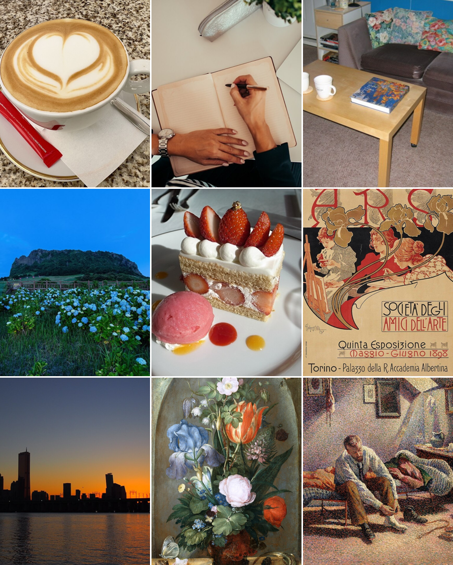

In [2]:
def clean(img, long_side=512):
    """RGB로 바꾸고 긴 변을 줄인 뒤, 픽셀만 새 이미지로 복사해 EXIF를 떼어 낸다."""
    img = img.convert("RGB")
    img.thumbnail((long_side, long_side))
    return Image.fromarray(np.asarray(img))


def load_folder(folder, limit=9):
    exts = {".jpg", ".jpeg", ".png", ".webp"}
    files = sorted(p for p in Path(folder).iterdir() if p.suffix.lower() in exts)[:limit]
    for p in files:
        if p.stat().st_size > 10 * 2**20:
            raise ValueError(f"{p.name}: 10MB가 넘는 파일은 받지 않습니다")
    if not files:
        raise FileNotFoundError(f"{folder}에 사진이 없습니다")
    return [clean(Image.open(p)) for p in files]


def make_grid(images, w=300, gap=3):
    """데모용: 사진 9장을 4:5 칸 3×3 그리드 캡처 한 장으로 만든다 (가운데 기준으로 잘라냄)."""
    h = w * 5 // 4
    grid = Image.new("RGB", (3 * w + 2 * gap, 3 * h + 2 * gap), "white")
    for i, im in enumerate(images[:9]):
        s = min(im.width / w, im.height / h)
        cw, ch = int(w * s), int(h * s)
        left, top = (im.width - cw) // 2, (im.height - ch) // 2
        tile = im.crop((left, top, left + cw, top + ch)).resize((w, h))
        grid.paste(tile, ((i % 3) * (w + gap), (i // 3) * (h + gap)))
    return grid


def split_grid(capture, margin=0.02):
    """그리드 캡처 한 장 → 3×3 등분 → 칸 가장자리를 잘라 사진 9장."""
    W, H = capture.size
    cells = []
    for r in range(3):
        for c in range(3):
            cell = capture.crop((c * W // 3, r * H // 3, (c + 1) * W // 3, (r + 1) * H // 3))
            mx, my = int(cell.width * margin), int(cell.height * margin)
            cells.append(clean(cell.crop((mx, my, cell.width - mx, cell.height - my))))
    return cells


raw = load_folder(SAMPLE_DIR)
capture = make_grid(raw)                                    # 사용자가 올리는 '피드 캡처' 역할
images = split_grid(capture) if len(raw) == 9 else raw      # 9장이 아니면 사진을 그대로 쓴다
bio = BIO.strip()[:150]
print(f"사진 {len(images)}장, 소개글 {len(bio)}자")
display(capture.resize((capture.width // 2, capture.height // 2)))

## [A] 색감 통계 (모델 없음)
- **팔레트:** 9장의 픽셀을 모아 KMeans(k=5) → 대표색 5개와 비율
- **밝기·채도:** HSV의 V, S 평균
- **통일감:** 사진별 RGB 히스토그램(8×8×8)끼리 겹치는 정도(히스토그램 교집합)의 평균. 나머지 사진과 가장 덜 겹치는 사진을 '튀는 사진'으로 기록한다.

{
 "palette": [
  [
   "#a48468",
   0.284
  ],
  [
   "#69534a",
   0.243
  ],
  [
   "#cdbea7",
   0.239
  ],
  [
   "#232821",
   0.187
  ],
  [
   "#1387ea",
   0.046
  ]
 ],
 "brightness": 0.567,
 "saturation": 0.369,
 "unity": 0.265,
 "outlier_photo": 4,
 "labels": [
  "사진마다 톤이 다르다"
 ]
}


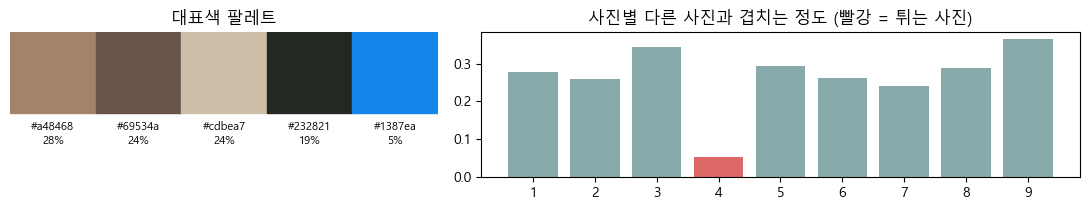

In [3]:
from sklearn.cluster import KMeans


def color_stats(images):
    small = [np.asarray(im.resize((128, 128))) for im in images]
    pixels = np.concatenate([s.reshape(-1, 3) for s in small]).astype(np.float32)

    km = KMeans(n_clusters=5, n_init="auto", random_state=0).fit(pixels[::4])   # 4픽셀마다 1개 표본
    share = np.bincount(km.labels_, minlength=5) / len(km.labels_)
    palette = [("#%02x%02x%02x" % tuple(int(v) for v in km.cluster_centers_[i]), round(float(share[i]), 3))
               for i in np.argsort(-share)]

    hsv = np.concatenate([np.asarray(Image.fromarray(s).convert("HSV")).reshape(-1, 3) for s in small]) / 255.0
    brightness, saturation = float(hsv[:, 2].mean()), float(hsv[:, 1].mean())

    hists = []
    for s in small:
        q = (s.reshape(-1, 3) // 32).astype(int)
        h = np.bincount(q[:, 0] * 64 + q[:, 1] * 8 + q[:, 2], minlength=512).astype(float)
        hists.append(h / h.sum())
    n = len(hists)
    inter = np.array([[np.minimum(hists[i], hists[j]).sum() for j in range(n)] for i in range(n)])
    unity = float(inter[np.triu_indices(n, 1)].mean())
    mean_to_others = (inter.sum(1) - 1) / (n - 1)           # 자기 자신(=1) 제외

    labels = []
    if brightness >= BRIGHT_HI: labels.append("밝은 톤")
    if brightness <= BRIGHT_LO: labels.append("어두운 톤")
    if saturation <= SAT_LO: labels.append("뮤트 톤")
    if saturation >= SAT_HI: labels.append("선명한 톤")
    if unity >= UNITY_HI: labels.append("톤이 고르다")
    if unity <= UNITY_LO: labels.append("사진마다 톤이 다르다")
    return {"palette": palette, "brightness": round(brightness, 3), "saturation": round(saturation, 3),
            "unity": round(unity, 3), "outlier_photo": int(mean_to_others.argmin()) + 1, "labels": labels,
            "per_photo_overlap": mean_to_others.round(3).tolist()}


color = color_stats(images)
print(json.dumps({k: v for k, v in color.items() if k != "per_photo_overlap"}, ensure_ascii=False, indent=1))

fig, axes = plt.subplots(1, 2, figsize=(11, 2.2), gridspec_kw={"width_ratios": [1, 1.4]})
for i, (hexc, share) in enumerate(color["palette"]):
    axes[0].add_patch(plt.Rectangle((i, 0), 1, 1, color=hexc))
    axes[0].text(i + 0.5, -0.1, f"{hexc}\n{share:.0%}", ha="center", va="top", fontsize=8)
axes[0].set_xlim(0, 5); axes[0].set_ylim(-0.8, 1); axes[0].axis("off"); axes[0].set_title("대표색 팔레트")
axes[1].bar(range(1, len(images) + 1), color["per_photo_overlap"], color="#8aa")
axes[1].bar(color["outlier_photo"], color["per_photo_overlap"][color["outlier_photo"] - 1], color="#d66")
axes[1].set_xticks(range(1, len(images) + 1)); axes[1].set_title("사진별 다른 사진과 겹치는 정도 (빨강 = 튀는 사진)")
plt.tight_layout(); plt.show()

## [B] CLIP 제로샷: 인상 키워드와 주제 (9장)
CLIP은 영어 모델이라 **한국어 라벨 ↔ 영어 프롬프트** 사전을 직접 만든다. 키워드마다 프롬프트 2개의 텍스트 임베딩을 평균한다(프롬프트 앙상블).

- **외모 관련 단어는 사전에 넣지 않는다.** 사전에 없으면 모델이 고를 수 없다.
- 사진마다 30개 키워드에 softmax → 9장 평균이 계정 점수. 분위기·성향 묶음에서 최소 2개씩 골라 top 5를 만든다.
- 키워드마다 점수가 가장 높은 사진 2장을 근거 사진으로 둔다.

In [4]:
def kw(id_, ko, group, *prompts):
    return {"id": id_, "ko": ko, "group": group, "prompts": list(prompts)}

KEYWORDS = [
    # 분위기 15
    kw("warm", "따뜻한", "분위기", "a warm and cozy photo", "a photo with warm, soft light"),
    kw("calm", "차분한", "분위기", "a calm and quiet photo", "a peaceful, still scene"),
    kw("lively", "활기찬", "분위기", "an energetic and lively photo", "a busy, vibrant scene"),
    kw("clean", "깔끔한", "분위기", "a clean and minimal photo", "a tidy, simple composition"),
    kw("emotional", "감성적인", "분위기", "an emotional, film-like photo", "a moody, sentimental photo"),
    kw("dreamy", "몽환적인", "분위기", "a dreamy, hazy photo", "a soft-focus, ethereal scene"),
    kw("bright", "밝은", "분위기", "a bright and cheerful photo", "a well-lit, airy photo"),
    kw("chic", "세련된", "분위기", "a stylish and sophisticated photo", "an elegant, modern scene"),
    kw("natural", "자연스러운", "분위기", "a natural, candid photo", "an unposed everyday moment"),
    kw("cozy", "아늑한", "분위기", "a snug, homely interior", "a comfortable indoor space"),
    kw("bold", "강렬한", "분위기", "a bold, high-contrast photo", "a striking photo with strong colors"),
    kw("vintage", "빈티지한", "분위기", "a vintage, retro-style image", "an old-fashioned, classic picture"),
    kw("simple", "소박한", "분위기", "a modest, simple everyday scene", "a humble, unpretentious photo"),
    kw("fancy", "화려한", "분위기", "a colorful and luxurious image", "an ornate, extravagant scene"),
    kw("fresh", "시원한", "분위기", "a fresh, cool-toned photo", "an open, breezy outdoor view"),
    # 성향 15
    kw("professional", "전문적인", "성향", "a photo of professional work", "a businesslike, work-focused scene"),
    kw("meticulous", "꼼꼼한", "성향", "a neatly organized, detailed photo", "a carefully arranged scene"),
    kw("creative", "창의적인", "성향", "a creative and artistic image", "an original, imaginative design"),
    kw("playful", "유쾌한", "성향", "a funny and playful photo", "a lighthearted, humorous scene"),
    kw("free", "자유로운", "성향", "a carefree travel photo", "a spontaneous, free-spirited moment"),
    kw("diligent", "성실한", "성향", "a photo of studying or working hard", "a daily routine of steady work"),
    kw("adventurous", "도전적인", "성향", "an adventurous outdoor activity", "a photo of trying something new and bold"),
    kw("kind", "다정한", "성향", "a gentle, affectionate scene", "a kind and caring moment"),
    kw("intellectual", "지적인", "성향", "a photo of books and learning", "an intellectual, thoughtful scene"),
    kw("trendy", "트렌디한", "성향", "a trendy, fashionable photo", "a hip, popular spot"),
    kw("relaxed", "여유로운", "성향", "a relaxed, leisurely moment", "a slow, unhurried afternoon"),
    kw("passionate", "열정적인", "성향", "a passionate, intense scene", "a photo full of energy and drive"),
    kw("independent", "독립적인", "성향", "a solitary, self-reliant scene", "enjoying time alone"),
    kw("sociable", "사교적인", "성향", "a group of friends having fun together", "a social gathering"),
    kw("tasteful", "취향이 확실한", "성향", "a photo with a distinct personal style", "a curated, consistent aesthetic"),
]

TOPICS = [  # (한국어 라벨, CLIP 프롬프트)
    ("음식·카페", "a photo of food or drinks at a cafe"),
    ("여행·풍경", "a travel or landscape photo"),
    ("작업물·포트폴리오", "a photo of a work project, design, or portfolio"),
    ("일상", "an ordinary everyday life snapshot"),
    ("반려동물", "a photo of a pet"),
    ("운동", "a photo of exercise or sports"),
    ("공부", "a photo of studying with books or notes"),
    ("행사·모임", "a photo of an event or gathering"),
    ("패션", "a fashion or outfit photo"),
    ("예술·문화", "a painting, an art poster, or an artwork in a museum"),
    ("사람·셀카", "a selfie or portrait of a person"),
    ("텍스트·공지", "a screenshot or notice made mostly of written text"),
]

assert len(KEYWORDS) == 30 and len({k["ko"] for k in KEYWORDS}) == 30
assert not [k["ko"] for k in KEYWORDS if any(b in k["ko"] for b in BANNED)], "키워드 사전에 외모 관련 단어가 있다"
print(f"키워드 {len(KEYWORDS)}개 (분위기 {sum(k['group'] == '분위기' for k in KEYWORDS)}, "
      f"성향 {sum(k['group'] == '성향' for k in KEYWORDS)}) · 주제 {len(TOPICS)}개")

키워드 30개 (분위기 15, 성향 15) · 주제 12개


첫인상 키워드 top 5
  화려한      [분위기] 점수 0.2511 · 근거 사진 [8, 5]
  전문적인     [성향] 점수 0.0785 · 근거 사진 [2, 1]
  아늑한      [분위기] 점수 0.0756 · 근거 사진 [3, 9]
  빈티지한     [분위기] 점수 0.0747 · 근거 사진 [9, 6]
  성실한      [성향] 점수 0.0490 · 근거 사진 [2, 1]
주제 분포: {'텍스트·공지': 3, '음식·카페': 2, '공부': 2, '여행·풍경': 2}


,사진,주제,가장 강한 키워드,확률
0,1,음식·카페,독립적인,0.126
1,2,공부,전문적인,0.439
2,3,공부,아늑한,0.574
3,4,여행·풍경,시원한,0.261
4,5,음식·카페,화려한,0.768
5,6,텍스트·공지,화려한,0.446
6,7,여행·풍경,시원한,0.149
7,8,텍스트·공지,화려한,0.841
8,9,텍스트·공지,빈티지한,0.331


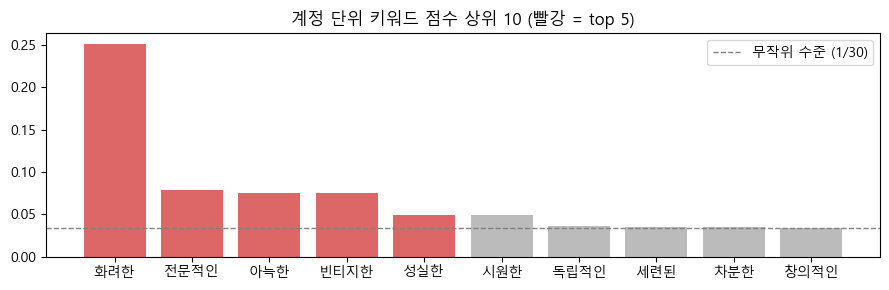

In [5]:
from transformers import CLIPModel, CLIPProcessor

clip_proc = CLIPProcessor.from_pretrained(CLIP_ID)
clip_model = CLIPModel.from_pretrained(CLIP_ID, dtype=torch.float16).to(DEVICE).eval()


@torch.no_grad()
def clip_probs(images, label_prompts):
    """사진 × 라벨 확률. 라벨마다 프롬프트 여러 개의 임베딩을 평균한다 (프롬프트 앙상블)."""
    flat = [p for g in label_prompts for p in g]
    inp = clip_proc(text=flat, images=images, return_tensors="pt", padding=True).to(DEVICE)
    inp["pixel_values"] = inp["pixel_values"].to(torch.float16)
    out = clip_model(**inp)
    img = out.image_embeds.float()
    img = img / img.norm(dim=-1, keepdim=True)
    txt = out.text_embeds.float()
    T, i = [], 0
    for g in label_prompts:
        v = txt[i:i + len(g)].mean(0)
        T.append(v / v.norm())
        i += len(g)
    logits = clip_model.logit_scale.exp().float() * img @ torch.stack(T).T
    return logits.softmax(dim=1).cpu().numpy()


def pick_top5(scores):
    """분위기·성향에서 2개씩 + 나머지 중 최고 1개 → 점수순."""
    order = list(np.argsort(-scores))
    chosen = []
    for grp in ("분위기", "성향"):
        chosen += [i for i in order if KEYWORDS[i]["group"] == grp][:2]
    chosen.append(next(i for i in order if i not in chosen))
    return sorted(chosen, key=lambda i: -scores[i])


kw_p = clip_probs(images, [k["prompts"] for k in KEYWORDS])   # (사진 수, 30)
tp_p = clip_probs(images, [[p] for _, p in TOPICS])            # (사진 수, 12)
scores = kw_p.mean(0)

clip = {
    "scores": {k["id"]: round(float(s), 4) for k, s in zip(KEYWORDS, scores)},
    "top5": [{"id": KEYWORDS[i]["id"], "ko": KEYWORDS[i]["ko"], "group": KEYWORDS[i]["group"],
              "score": round(float(scores[i]), 4),
              "photos": [int(j) + 1 for j in np.argsort(-kw_p[:, i])[:2]]} for i in pick_top5(scores)],
    "topics": dict(Counter(TOPICS[j][0] for j in tp_p.argmax(1)).most_common()),
    "per_photo": kw_p.round(4).tolist(),
}

print("첫인상 키워드 top 5")
for k in clip["top5"]:
    print(f"  {k['ko']:<8} [{k['group']}] 점수 {k['score']:.4f} · 근거 사진 {k['photos']}")
print("주제 분포:", clip["topics"])

per_photo = pd.DataFrame({
    "사진": range(1, len(images) + 1),
    "주제": [TOPICS[j][0] for j in tp_p.argmax(1)],
    "가장 강한 키워드": [KEYWORDS[j]["ko"] for j in kw_p.argmax(1)],
    "확률": kw_p.max(1).round(3),
})
display(per_photo)

top10 = np.argsort(-scores)[:10]
chosen = {k["id"] for k in clip["top5"]}
plt.figure(figsize=(9, 3))
plt.bar([KEYWORDS[i]["ko"] for i in top10], scores[top10],
        color=["#d66" if KEYWORDS[i]["id"] in chosen else "#bbb" for i in top10])
plt.axhline(1 / len(KEYWORDS), ls="--", c="gray", lw=1, label="무작위 수준 (1/30)")
plt.title("계정 단위 키워드 점수 상위 10 (빨강 = top 5)"); plt.legend(); plt.tight_layout(); plt.show()

## [C] BLIP-2 사진 캡션 (9장)
사진마다 영어 캡션을 한 줄씩 뽑아 EXAONE이 "무엇이 찍혔는지"를 알 수 있게 한다. 8bit로 올리고(약 4GB), 끝나면 바로 내린다.

- 8bit 로드에는 `dtype=torch.float16`을 같이 넘긴다. 안 넘기면 토큰마다 dtype 변환 경고가 쏟아진다.
- `USE_CAPTION = False`면 건너뛴다. 캡션이 없어도 리포트는 나온다.

In [6]:
captions = []
if USE_CAPTION:
    from transformers import BitsAndBytesConfig, Blip2ForConditionalGeneration, Blip2Processor

    t0 = time.time()
    blip_proc = Blip2Processor.from_pretrained(BLIP_ID)
    blip = Blip2ForConditionalGeneration.from_pretrained(
        BLIP_ID, quantization_config=BitsAndBytesConfig(load_in_8bit=True),
        dtype=torch.float16, device_map=DEVICE)
    print(f"BLIP-2 로드 {time.time() - t0:.0f}초, GPU {torch.cuda.memory_allocated() / 2**30:.2f} GB")

    with torch.no_grad():
        inp = blip_proc(images=images, return_tensors="pt").to(DEVICE, torch.float16)
        ids = blip.generate(**inp, max_new_tokens=30)
    captions = [c.strip() for c in blip_proc.batch_decode(ids, skip_special_tokens=True)]

    del blip, blip_proc, inp, ids
    free_gpu()

for i, c in enumerate(captions, 1):
    print(f"{i}. {c}")

BLIP-2 로드 16초, GPU 4.22 GB


GPU 사용량: 0.30 GB
1. a cappuccino with a heart shape in the middle
2. woman writing in notebook
3. a brown couch
4. a field of blue flowers and a mountain in the background
5. a strawberry and cream dessert on a white plate
6. an old poster advertising the arts
7. a city skyline at sunset with the sun setting behind it
8. a painting of flowers in a vase on a table
9. a painting of a man sitting on a bed in a room


## [D] 소개글 톤 분류: 임베딩 제로샷 분류 (4장)
톤 라벨마다 설명문을 쓰고, 소개글 임베딩과 코사인 유사도가 가장 높은 라벨을 고른다. 글자 수·이모지·해시태그·링크·직무 키워드 같은 표면 특징도 함께 센다.

In [7]:
from sentence_transformers import SentenceTransformer

embedder = SentenceTransformer(EMBED_ID, device="cpu")   # GPU는 CLIP·EXAONE 몫으로 남긴다

TONES = {
    "전문적": "직무, 경력, 전공, 포트폴리오를 단정하게 소개하는 글",
    "친근": "반말이나 구어체로 가볍게 인사하고 일상을 나누는 글",
    "유머": "농담, 밈, 장난스러운 표현으로 웃음을 주는 글",
    "감성": "분위기, 감정, 짧은 시 같은 문장으로 좋아하는 것과 느낌을 전하는 글",
    "미니멀": "이모지나 단어 몇 개만 있는 아주 짧은 글",
}
tone_vecs = embedder.encode(list(TONES.values()), normalize_embeddings=True, show_progress_bar=False)
EMOJI = re.compile("[\U0001F300-\U0001FAFF\u2600-\u27BF]")


def classify_tone(bio):
    feats = {"length": len(bio), "emoji": len(EMOJI.findall(bio)), "hashtag": bio.count("#"),
             "link": bool(re.search(r"https?://|www\.|\.com|\.kr|\.so|linktr", bio)),
             "job_keyword": any(w in bio for w in JOB_WORDS)}
    if not bio:
        return {"label": "없음", "scores": {}, **feats}
    sims = tone_vecs @ embedder.encode([bio], normalize_embeddings=True, show_progress_bar=False)[0]
    names = list(TONES)
    return {"label": names[int(sims.argmax())], "scores": {n: round(float(s), 3) for n, s in zip(names, sims)}, **feats}


tone = classify_tone(bio)
print(f"소개글: {bio}")
print(json.dumps(tone, ensure_ascii=False, indent=1))

소개글: ☕🌷✈️ 좋아하는 것들로 채우는 하루 | 커피 · 여행 · 전시
{
 "label": "감성",
 "scores": {
  "전문적": 0.43,
  "친근": 0.446,
  "유머": 0.459,
  "감성": 0.564,
  "미니멀": 0.411
 },
 "length": 35,
 "emoji": 3,
 "hashtag": 0,
 "link": false,
 "job_keyword": false
}


## [E] 가이드 카드 하이브리드 검색: RAG (8장)
개선안이 근거 없이 지어지지 않도록, 피드 운영 팁을 카드로 만들어 두고 분석 결과로 검색한다. 졸업요건 RAG 챗봇과 같은 방식이다.

- **벡터 검색:** bge-m3 코사인 유사도
- **키워드 검색:** 한국어 글자 2-gram BM25 (조사가 붙어도 맞도록)
- **합치기:** RRF, 영역(대표 이미지·색감·소개글)마다 상위 2장

> 카드 12장은 직접 쓴 초안이다. 발표 전에 공개된 브랜딩 가이드로 출처를 보강하고 40장 안팎으로 늘린다.

In [8]:
from rank_bm25 import BM25Okapi

AREAS = ["대표 이미지", "색감", "소개글"]
SRC = "직접 작성(초안), 출처 보강 예정"

def card(id_, area, title, content):
    return {"id": id_, "area": area, "title": title, "content": content, "source": SRC}

GUIDE_CARDS = [
    card("G01", "대표 이미지", "첫 줄 3장이 첫인상을 정한다",
         "프로필을 연 사람은 스크롤하기 전에 맨 윗줄 3장을 먼저 본다. 보여주고 싶은 인상에 가장 가까운 사진을 이 자리에 둔다. 게시물 고정 기능을 쓰면 올린 순서를 바꾸지 않고도 첫 줄을 정할 수 있다."),
    card("G02", "대표 이미지", "주제가 한눈에 보이게",
         "9장 중 한 주제가 절반 가까이 되면 무엇을 하는 사람인지가 빨리 읽힌다. 주제가 너무 흩어져 있으면 대표 주제 1~2개를 정하고 나머지는 하이라이트로 옮긴다."),
    card("G03", "대표 이미지", "작업물은 결과와 과정을 함께",
         "포트폴리오 성격의 사진은 완성본 한 장보다 과정이나 도구가 보이는 사진과 섞을 때 전문성이 더 잘 전달된다. 작업 책상, 스케치, 기획 노트 같은 컷을 첫 화면에 하나 둔다."),
    card("G04", "대표 이미지", "사람의 흔적이 보이는 컷 하나",
         "사물과 풍경만 이어지면 거리감이 느껴질 수 있다. 손이나 뒷모습처럼 사람이 살짝 보이는 컷을 하나 넣으면 친근함이 생긴다."),
    card("G05", "색감", "톤을 하나로 맞추기",
         "사진마다 밝기와 색 온도가 다르면 피드가 산만해 보인다. 같은 보정 프리셋이나 필터 하나를 정해 모든 사진에 적용하면 통일감이 커진다."),
    card("G06", "색감", "튀는 사진 한 장 다루기",
         "전체 톤과 크게 다른 사진이 하나 있으면 그 사진에 눈이 먼저 간다. 보정으로 밝기와 색을 맞추거나, 첫 화면 아래쪽으로 내린다."),
    card("G07", "색감", "대표색 2~3개 정하기",
         "자주 쓰는 색을 2~3개로 정해 두고 배경과 소품을 그 안에서 고르면 계정만의 색이 생긴다. 팔레트에서 이미 많이 쓰는 색을 출발점으로 삼는다."),
    card("G08", "색감", "밝기 대비로 리듬 만들기",
         "비슷한 사진만 이어지면 단조로울 수 있다. 밝은 사진과 어두운 사진을 체크무늬처럼 번갈아 두면 톤은 지키면서 리듬이 생긴다."),
    card("G09", "소개글", "첫 줄에 무엇을 하는 사람인지",
         "소개글 첫 줄은 이름보다 하는 일이나 관심 분야를 한 줄로 쓰는 편이 기억에 남는다. 예를 들어 '브랜드 마케팅을 공부하는 대학생'처럼 쓴다."),
    card("G10", "소개글", "직무 키워드 넣기",
         "취업이나 협업이 목적이면 마케팅, 콘텐츠 기획처럼 직무와 전공 키워드를 넣어야 검색에도 걸리고 첫인상도 분명해진다."),
    card("G11", "소개글", "링크로 다음 행동 열어 두기",
         "포트폴리오, 블로그, 노션 링크를 하나 걸어 두면 관심이 생긴 사람이 더 볼 곳이 생긴다. 링크가 무엇인지 한 단어로 설명을 붙인다."),
    card("G12", "소개글", "이모지는 구분 기호로만",
         "이모지는 항목을 나누는 정도로 1~3개만 쓰면 깔끔하다. 이모지가 많으면 정작 전하려는 내용이 묻힌다."),
]
assert not [c["id"] for c in GUIDE_CARDS if any(b in c["title"] + c["content"] for b in BANNED)]


def bigrams(text):
    t = re.sub(r"\s+", "", text)
    return [t[i:i + 2] for i in range(len(t) - 1)] or [t]


card_texts = [f"{c['title']}\n{c['content']}" for c in GUIDE_CARDS]
card_vecs = embedder.encode(card_texts, normalize_embeddings=True, show_progress_bar=False)
bm25 = BM25Okapi([bigrams(t) for t in card_texts])


def search_cards(query, area, k=2, rrf_k=60):
    """영역 안에서 벡터 순위와 BM25 순위를 RRF로 합쳐 상위 k장."""
    idx = [i for i, c in enumerate(GUIDE_CARDS) if c["area"] == area]
    q = embedder.encode([query], normalize_embeddings=True, show_progress_bar=False)[0]
    dense = sorted(idx, key=lambda i: -float(card_vecs[i] @ q))
    bm = bm25.get_scores(bigrams(query))
    sparse = sorted(idx, key=lambda i: -bm[i])
    fused = {i: 1 / (rrf_k + dense.index(i) + 1) + 1 / (rrf_k + sparse.index(i) + 1) for i in idx}
    return [GUIDE_CARDS[i] for i in sorted(idx, key=lambda i: -fused[i])[:k]]


def build_queries(color, clip, tone):
    kws = ", ".join(k["ko"] for k in clip["top5"])
    topics = ", ".join(f"{t} {n}" for t, n in clip["topics"].items())
    level = "낮음" if color["unity"] <= UNITY_LO else ("높음" if color["unity"] >= UNITY_HI else "보통")
    return {
        "대표 이미지": f"대표 이미지 첫 줄 구성. 주제 분포: {topics}. 키워드: {kws}",
        "색감": f"피드 색감 통일. 통일감 {color['unity']} {level}, {', '.join(color['labels']) or '보통 톤'}, "
               f"튀는 사진 {color['outlier_photo']}번",
        "소개글": f"소개글 작성. 톤 {tone['label']}, 직무 키워드 {'있음' if tone['job_keyword'] else '없음'}, "
               f"링크 {'있음' if tone['link'] else '없음'}, 이모지 {tone['emoji']}개, {tone['length']}자",
    }


queries = build_queries(color, clip, tone)
cards = [c for area in AREAS for c in search_cards(queries[area], area)]
for area in AREAS:
    print(f"[{area}] 질의: {queries[area]}")
    for c in cards:
        if c["area"] == area:
            print(f"    → {c['id']} {c['title']}")

[대표 이미지] 질의: 대표 이미지 첫 줄 구성. 주제 분포: 텍스트·공지 3, 음식·카페 2, 공부 2, 여행·풍경 2. 키워드: 화려한, 전문적인, 아늑한, 빈티지한, 성실한
    → G02 주제가 한눈에 보이게
    → G03 작업물은 결과와 과정을 함께
[색감] 질의: 피드 색감 통일. 통일감 0.265 낮음, 사진마다 톤이 다르다, 튀는 사진 4번
    → G05 톤을 하나로 맞추기
    → G06 튀는 사진 한 장 다루기
[소개글] 질의: 소개글 작성. 톤 감성, 직무 키워드 없음, 링크 없음, 이모지 3개, 35자
    → G10 직무 키워드 넣기
    → G12 이모지는 구분 기호로만


## [F] EXAONE 리포트 생성: ICL + JSON 출력 (6장)
**원칙: 키워드는 CLIP이 고르고, EXAONE은 고른 이유를 설명만 한다.** 프롬프트에 top 5만 넣고, 가상 계정 예시 2개(ICL)로 출력 형식과 말투를 보여 준다.

로드 설정은 졸업요건 RAG 챗봇·프롬프트 엔지니어링 과제와 같다.
- 4bit NF4 + `dtype=torch.bfloat16` (config의 float32를 따르면 8GB를 넘는다)
- transformers 5에서 EXAONE 원격 코드가 쓰는 `create_causal_mask` 인자 이름이 바뀌어 호환 패치를 넣는다
- 어텐션은 `sdpa`로 고정하고, SDPA의 GQA 경로를 끈다. 켜 두면 프롬프트가 길 때(캡션 포함 약 3000토큰) VRAM 8GB를 넘겨 생성이 멈춘다
- 로드할 때 `[ERROR] cache_position is part of ExaoneModel.forward's signature, but not documented` 문구가 찍히는데, 원격 코드의 문서화(docstring) 검사 메시지라 생성 결과와는 관계없다

In [9]:
import inspect
import sys

from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig, GenerationConfig


def patch_exaone_for_transformers5():
    """EXAONE-3.5 원격 코드 × transformers 5 호환: input_embeds → inputs_embeds, 없어진 인자는 버린다."""
    import transformers.masking_utils as mu
    orig = getattr(mu, "_orig_create_causal_mask", mu.create_causal_mask)
    allowed = set(inspect.signature(orig).parameters)
    if not ("inputs_embeds" in allowed and "input_embeds" not in allowed):
        return

    def compat(*args, **kwargs):
        if "input_embeds" in kwargs and "inputs_embeds" not in kwargs:
            kwargs["inputs_embeds"] = kwargs.pop("input_embeds")
        for k in [k for k in kwargs if k not in allowed]:
            kwargs.pop(k)
        return orig(*args, **kwargs)

    mu._orig_create_causal_mask = orig
    mu.create_causal_mask = compat
    for name, m in list(sys.modules.items()):       # 이미 import된 원격 모듈에도 다시 꽂는다
        if name.startswith("transformers_modules") and hasattr(m, "create_causal_mask"):
            m.create_causal_mask = compat


# SDPA에 enable_gqa=True를 넘기면 이 GPU(RTX 50, torch 2.7)에서는 메모리 효율 커널을 못 쓰고 math 경로로 빠져
# 층마다 32×n×n fp32 행렬을 만든다(3000토큰이면 1.1GB → 8GB 초과, 생성이 멈추거나 CUBLAS 오류).
# GQA 경로를 끄면 transformers가 key/value를 반복해서 넘기고, 메모리 효율 커널이 쓰인다(3000토큰 prefill 3.2GB → 0.8GB).
import transformers.integrations.sdpa_attention as sdpa_attention
sdpa_attention.use_gqa_in_sdpa = lambda *args, **kwargs: False

t0 = time.time()
patch_exaone_for_transformers5()
llm_tok = AutoTokenizer.from_pretrained(LLM_ID, trust_remote_code=True)
llm = AutoModelForCausalLM.from_pretrained(
    LLM_ID, trust_remote_code=True, device_map="auto", dtype=torch.bfloat16, attn_implementation="sdpa",
    quantization_config=BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                                           bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=torch.bfloat16))
patch_exaone_for_transformers5()                    # 로드 중 새로 import된 원격 모듈에도 적용
llm.eval()
# 그리디 디코딩: 샘플링 관련 값을 기본값으로 덮어써야 경고가 나오지 않는다
GEN_CFG = GenerationConfig.from_dict({
    **llm.generation_config.to_dict(), "max_new_tokens": 1024, "do_sample": False,
    "temperature": 1.0, "top_p": 1.0, "top_k": 50, "repetition_penalty": 1.05,
    "pad_token_id": llm_tok.pad_token_id or llm_tok.eos_token_id})
print(f"EXAONE 로드 {time.time() - t0:.0f}초")
free_gpu()


@torch.no_grad()
def chat(messages):
    prompt = llm_tok.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = llm_tok([prompt], return_tensors="pt").to(llm.device)
    out = llm.generate(**inputs, generation_config=GEN_CFG)
    return llm_tok.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True,
                          clean_up_tokenization_spaces=False).strip()

[transformers] The `check_model_inputs` decorator is deprecated in favor of `merge_with_config_defaults`.


[ERROR] `cache_position` is part of ExaoneModel.forward's signature, but not documented. Make sure to add it to the docstring of the function in C:\Users\sm757\.cache\huggingface\modules\transformers_modules\LGAI_hyphen_EXAONE\EXAONE_hyphen_3_dot_5_hyphen_7_dot_8B_hyphen_Instruct\553ea250b9a5317231459279d5847d6cf955b9aa\modeling_exaone.py.
[ERROR] `cache_position` is part of ExaoneForCausalLM.forward's signature, but not documented. Make sure to add it to the docstring of the function in C:\Users\sm757\.cache\huggingface\modules\transformers_modules\LGAI_hyphen_EXAONE\EXAONE_hyphen_3_dot_5_hyphen_7_dot_8B_hyphen_Instruct\553ea250b9a5317231459279d5847d6cf955b9aa\modeling_exaone.py.


EXAONE 로드 29초


GPU 사용량: 5.21 GB


In [10]:
SYSTEM = """너는 처음 이 계정을 본 사람의 시선으로 인스타그램 피드의 첫인상을 설명하는 브랜딩 코치다.
규칙:
1. 외모, 얼굴, 체형, 나이 등 사람의 생김새는 절대 말하지 않는다. 사진의 색감, 구도, 주제, 분위기와 글의 톤만 말한다.
2. summary는 60자 안팎의 한 문장으로 쓴다.
3. keywords에는 [첫인상 키워드 top 5]의 5개만 그 순서대로 쓴다. 키워드를 부정하지 말고 왜 그렇게 보이는지를 1~2문장으로 설명한다. photos에는 근거 사진 번호를 넣고, reason에서 사진 번호를 말할 때는 photos의 번호와 [사진 캡션] 내용만 쓴다.
4. suggestions는 대표 이미지, 색감, 소개글 영역마다 정확히 하나씩 쓴다. action은 사진 번호나 바꿀 문장을 넣어 구체적으로 쓰고, source에는 [가이드 카드]에서 같은 영역 카드 id 하나를 쓴다.
5. 아래 JSON 형식만 출력한다. 다른 설명이나 코드 블록 표시는 붙이지 않는다.
{"summary": "...", "keywords": [{"word": "...", "reason": "...", "photos": [1]}], "suggestions": [{"area": "대표 이미지", "action": "...", "why": "...", "source": "G01"}]}"""

ICL_EXAMPLES = [
    ("""[첫인상 키워드 top 5] 깔끔한(0.074, 사진 2·5), 차분한(0.069, 사진 1·5), 전문적인(0.066, 사진 2·8), 꼼꼼한(0.061, 사진 8·2), 세련된(0.058, 사진 5·1)
[사진 캡션]
  1. a white desk with a laptop and a plant
  2. a presentation slide on a monitor
  3. a cup of black coffee on a table
  4. a street at night with neon lights
  5. a minimal white room with a chair
  6. a conference hall with a stage
  7. a notebook with handwritten notes
  8. a design mockup on a tablet
  9. a city skyline in the evening
[색감] 팔레트 #f2f2f0 34%, #2b2b2b 21%, #a9b4bd 18%, #6e7a85 15%, #d9c3a5 12% / 밝기 0.71, 채도 0.18, 통일감 0.63 (밝은 톤, 뮤트 톤, 톤이 고르다), 튀는 사진 4번
[주제 분포] 작업물·포트폴리오 4, 일상 3, 여행·풍경 2
[소개글] "콘텐츠 마케터 | 브랜드 이야기를 기록합니다 🔗 notion.so/portfolio" / 톤: 전문적, 직무 키워드 있음, 링크 있음
[가이드 카드]
  G03 [대표 이미지] 작업물은 결과와 과정을 함께: 포트폴리오 성격의 사진은 과정이나 도구가 보이는 사진과 섞을 때 전문성이 더 잘 전달된다.
  G06 [색감] 튀는 사진 한 장 다루기: 전체 톤과 크게 다른 사진은 보정으로 맞추거나 첫 화면 아래쪽으로 내린다.
  G12 [소개글] 이모지는 구분 기호로만: 이모지는 항목을 나누는 정도로 1~3개만 쓰면 깔끔하다.""",
     """{"summary": "밝고 정돈된 작업 공간이 먼저 보여, 일을 차분하고 꼼꼼하게 하는 마케터라는 인상을 준다.", "keywords": [{"word": "깔끔한", "reason": "흰 벽과 정리된 책상이 반복되어 군더더기 없는 인상을 준다.", "photos": [2, 5]}, {"word": "차분한", "reason": "채도가 낮은 흰색·회색 톤이 많아 조용하고 안정된 분위기다.", "photos": [1, 5]}, {"word": "전문적인", "reason": "발표 자료와 디자인 시안이 보여 일하는 사람이라는 점이 먼저 읽힌다.", "photos": [2, 8]}, {"word": "꼼꼼한", "reason": "시안과 슬라이드가 정돈된 구도로 찍혀 있어 세심하게 준비하는 사람처럼 보인다.", "photos": [8, 2]}, {"word": "세련된", "reason": "여백이 많은 미니멀한 공간 사진이 현대적인 느낌을 더한다.", "photos": [5, 1]}], "suggestions": [{"area": "대표 이미지", "action": "결과물 사진 2번 옆에 손글씨 기획 노트 7번을 첫 줄로 올려 결과와 과정을 함께 보여 주기", "why": "완성본만 있으면 과정이 보이지 않아 실력이 덜 전달된다.", "source": "G03"}, {"area": "색감", "action": "네온 조명 야경 4번은 밝기를 올리고 채도를 낮춰 다른 사진과 톤을 맞추거나 아래쪽으로 내리기", "why": "밝은 뮤트 톤 사이에서 어둡고 선명한 4번만 튄다.", "source": "G06"}, {"area": "소개글", "action": "지금 소개글은 직무와 링크가 이미 있어 좋다. 🔗 하나만 남기고 줄바꿈으로 직무와 링크를 나누기", "why": "구분만 정리하면 핵심 정보가 더 빨리 읽힌다.", "source": "G12"}]}"""),
    ("""[첫인상 키워드 top 5] 활기찬(0.062, 사진 3·6), 유쾌한(0.058, 사진 6·9), 화려한(0.055, 사진 3·4), 자유로운(0.054, 사진 2·7), 사교적인(0.051, 사진 9·6)
[사진 캡션]
  1. a plate of fried chicken
  2. a beach with people swimming
  3. colorful fireworks over a river
  4. a screenshot of a video game
  5. a dog sleeping on a sofa
  6. friends laughing at a party
  7. a mountain trail in autumn
  8. a screenshot of a chat message
  9. a karaoke room with colorful lights
[색감] 팔레트 #1d1b2e 26%, #e8a33c 20%, #4f7fb8 19%, #c94f5c 18%, #e9e4dc 17% / 밝기 0.52, 채도 0.58, 통일감 0.29 (선명한 톤, 사진마다 톤이 다르다), 튀는 사진 8번
[주제 분포] 일상 3, 행사·모임 3, 여행·풍경 2, 텍스트·공지 1
[소개글] "(없음)" / 톤: 없음, 직무 키워드 없음, 링크 없음
[가이드 카드]
  G02 [대표 이미지] 주제가 한눈에 보이게: 주제가 너무 흩어져 있으면 대표 주제 1~2개를 정하고 나머지는 하이라이트로 옮긴다.
  G05 [색감] 톤을 하나로 맞추기: 같은 보정 프리셋이나 필터 하나를 정해 모든 사진에 적용하면 통일감이 커진다.
  G09 [소개글] 첫 줄에 무엇을 하는 사람인지: 소개글 첫 줄은 하는 일이나 관심 분야를 한 줄로 쓰는 편이 기억에 남는다.""",
     """{"summary": "모임과 여행이 가득해 즐겁게 사는 사람으로 보이지만, 무엇을 하는 사람인지는 잘 드러나지 않는다.", "keywords": [{"word": "활기찬", "reason": "불꽃놀이와 파티 사진이 강한 색과 움직임으로 에너지를 준다.", "photos": [3, 6]}, {"word": "유쾌한", "reason": "웃고 떠드는 모임과 노래방 장면이 가볍고 즐거운 분위기를 만든다.", "photos": [6, 9]}, {"word": "화려한", "reason": "불꽃과 게임 화면처럼 색이 많은 사진이 눈에 띈다.", "photos": [3, 4]}, {"word": "자유로운", "reason": "바다와 산길 사진이 여기저기 떠나는 사람이라는 느낌을 준다.", "photos": [2, 7]}, {"word": "사교적인", "reason": "여럿이 함께한 장면이 반복되어 사람을 좋아하는 계정으로 보인다.", "photos": [9, 6]}], "suggestions": [{"area": "대표 이미지", "action": "캡처 이미지 4번과 8번은 하이라이트로 옮기고, 여행·모임 사진 2, 3, 6번을 첫 줄에 모아 주제를 분명히 하기", "why": "주제가 흩어져 있어 어떤 사람인지 한눈에 읽히지 않는다.", "source": "G02"}, {"area": "색감", "action": "필터 하나를 정해 2, 3, 6, 7번부터 같은 보정을 적용하기", "why": "선명한 사진과 어두운 사진이 섞여 통일감이 낮다.", "source": "G05"}, {"area": "소개글", "action": "비어 있는 소개글 첫 줄에 '사람과 여행을 기록하는 ○○학과 학생'처럼 하는 일과 관심사를 한 줄로 쓰기", "why": "소개글이 없으면 사진만으로는 무엇을 하는 사람인지 알 수 없다.", "source": "G09"}]}"""),
]


def format_input(color, clip, captions, tone, bio, cards):
    kws = ", ".join(f"{k['ko']}({k['score']:.3f}, 사진 {'·'.join(map(str, k['photos']))})" for k in clip["top5"])
    cap = "\n".join(f"  {i}. {c}" for i, c in enumerate(captions, 1)) or "  (캡션 없음)"
    pal = ", ".join(f"{h} {s:.0%}" for h, s in color["palette"])
    topics = ", ".join(f"{t} {n}" for t, n in clip["topics"].items())
    card_txt = "\n".join(f"  {c['id']} [{c['area']}] {c['title']}: {c['content']}" for c in cards)
    return (f"[첫인상 키워드 top 5] {kws}\n[사진 캡션]\n{cap}\n"
            f"[색감] 팔레트 {pal} / 밝기 {color['brightness']}, 채도 {color['saturation']}, 통일감 {color['unity']} "
            f"({', '.join(color['labels']) or '보통'}), 튀는 사진 {color['outlier_photo']}번\n"
            f"[주제 분포] {topics}\n"
            f"[소개글] \"{bio or '(없음)'}\" / 톤: {tone['label']}, 직무 키워드 {'있음' if tone['job_keyword'] else '없음'}, "
            f"링크 {'있음' if tone['link'] else '없음'}\n[가이드 카드]\n{card_txt}")


# ICL 예시 답이 올바른 JSON인지 먼저 확인 (예시가 깨져 있으면 모델도 깨진 형식을 배운다)
for _, a in ICL_EXAMPLES:
    json.loads(a)

user_msg = format_input(color, clip, captions, tone, bio, cards)
messages = [{"role": "system", "content": SYSTEM}]
for u, a in ICL_EXAMPLES:
    messages += [{"role": "user", "content": u}, {"role": "assistant", "content": a}]
messages.append({"role": "user", "content": user_msg})
print(user_msg)

[첫인상 키워드 top 5] 화려한(0.251, 사진 8·5), 전문적인(0.079, 사진 2·1), 아늑한(0.076, 사진 3·9), 빈티지한(0.075, 사진 9·6), 성실한(0.049, 사진 2·1)
[사진 캡션]
  1. a cappuccino with a heart shape in the middle
  2. woman writing in notebook
  3. a brown couch
  4. a field of blue flowers and a mountain in the background
  5. a strawberry and cream dessert on a white plate
  6. an old poster advertising the arts
  7. a city skyline at sunset with the sun setting behind it
  8. a painting of flowers in a vase on a table
  9. a painting of a man sitting on a bed in a room
[색감] 팔레트 #a48468 28%, #69534a 24%, #cdbea7 24%, #232821 19%, #1387ea 5% / 밝기 0.567, 채도 0.369, 통일감 0.265 (사진마다 톤이 다르다), 튀는 사진 4번
[주제 분포] 텍스트·공지 3, 음식·카페 2, 공부 2, 여행·풍경 2
[소개글] "☕🌷✈️ 좋아하는 것들로 채우는 하루 | 커피 · 여행 · 전시" / 톤: 감성, 직무 키워드 없음, 링크 없음
[가이드 카드]
  G02 [대표 이미지] 주제가 한눈에 보이게: 9장 중 한 주제가 절반 가까이 되면 무엇을 하는 사람인지가 빨리 읽힌다. 주제가 너무 흩어져 있으면 대표 주제 1~2개를 정하고 나머지는 하이라이트로 옮긴다.
  G03 [대표 이미지] 작업물은 결과와 과정을 함께: 포트폴리오 성격의 사진은 완성본 한 장보다 과정이나 도구가 보이는 사진과 섞을 때 전문성이 더 잘 전달된다.

## [V] 검증과 대체 경로
생성 결과를 그대로 믿지 않는다.

| 검사 | 실패 시 |
|---|---|
| JSON 파싱, 외모 금지어 | 1회 재생성 |
| 키워드가 top 5와 같은가 | 빠진 키워드는 규칙 문장, top 5 밖 키워드는 삭제 |
| 사진 번호가 1~9 안인가 | CLIP 근거 사진으로 교체 |
| 개선안이 영역마다 하나, 출처가 검색된 같은 영역 카드인가 | 카드 내용으로 규칙 문장 |

재생성해도 JSON이 안 나오면 CLIP top 5와 카드만으로 **규칙 기반 리포트**를 만든다. LLM이 실패해도 결과는 항상 나온다.

In [11]:
def parse_json(text):
    s, e = text.find("{"), text.rfind("}")
    if s < 0 or e <= s:
        return None
    try:
        obj = json.loads(text[s:e + 1])
    except json.JSONDecodeError:
        return None
    return obj if isinstance(obj, dict) else None


def has_banned(obj):
    s = obj if isinstance(obj, str) else json.dumps(obj, ensure_ascii=False)
    return [w for w in BANNED if w in s]


def rule_keyword(k):
    return {"word": k["ko"], "photos": k["photos"],
            "reason": f"사진 {'·'.join(map(str, k['photos']))}번에서 '{k['ko']}' 분위기가 가장 강하게 읽힌다."}


def rule_suggestion(c):
    return {"area": c["area"], "action": c["title"], "why": c["content"].split(". ")[0] + ".", "source": c["id"]}


def validate(report, clip, cards, n_photos):
    """LLM 출력을 규칙에 맞게 고친다. → (고친 리포트, 고친 내역)"""
    issues = []
    top_words = [k["ko"] for k in clip["top5"]]

    summary = report.get("summary")
    if not isinstance(summary, str) or not summary.strip() or has_banned(summary):
        issues.append("summary 없음/금지어 → 규칙 문장")
        summary = f"{top_words[0]}·{top_words[1]} 인상이 먼저 보이는 피드다."

    got = {k["word"]: k for k in report.get("keywords") or [] if isinstance(k, dict) and isinstance(k.get("word"), str)}
    keywords = []
    for k in clip["top5"]:
        item = got.get(k["ko"])
        if item is None or not isinstance(item.get("reason"), str) or has_banned(item):
            issues.append(f"키워드 '{k['ko']}' 없음/금지어 → 규칙 문장")
            keywords.append(rule_keyword(k))
            continue
        photos = [p for p in item.get("photos") or [] if isinstance(p, int) and 1 <= p <= n_photos]
        if not photos:
            issues.append(f"키워드 '{k['ko']}' 사진 번호 이상 → CLIP 근거 사진")
            photos = k["photos"]
        keywords.append({"word": k["ko"], "reason": item["reason"].strip(), "photos": photos})
    extra = [w for w in got if w not in top_words]
    if extra:
        issues.append(f"top 5 밖 키워드 삭제: {extra}")

    by_id = {c["id"]: c for c in cards}
    suggestions = []
    for area in AREAS:
        ok = [g for g in report.get("suggestions") or [] if isinstance(g, dict) and g.get("area") == area
              and isinstance(g.get("source"), str) and by_id.get(g["source"], {}).get("area") == area
              and isinstance(g.get("action"), str) and g["action"].strip() and not has_banned(g)]
        if ok:
            g = ok[0]
            suggestions.append({"area": area, "action": g["action"].strip(), "why": str(g.get("why", "")).strip(),
                                "source": g["source"]})
        else:
            issues.append(f"개선안 '{area}' 없음/출처 오류/금지어 → 카드 기반 규칙 문장")
            suggestions.append(rule_suggestion(next(c for c in cards if c["area"] == area)))
    return {"summary": summary.strip(), "keywords": keywords, "suggestions": suggestions}, issues


# 검증 함수 점검: 일부러 망가뜨린 리포트가 규칙대로 고쳐지는지 확인
_bad = {"keywords": [{"word": clip["top5"][0]["ko"], "reason": "얼굴이 밝아 보인다", "photos": [0, 12]},
                     {"word": "없는키워드", "reason": "x", "photos": [1]},
                     {"word": clip["top5"][1]["ko"], "reason": "좋다", "photos": [99]}],
        "suggestions": [{"area": "색감", "action": "필터 통일", "why": "", "source": "G99"},
                        {"area": "소개글", "action": "x", "source": ["G09"]}]}
_fixed, _issues = validate(_bad, clip, cards, len(images))
assert [k["word"] for k in _fixed["keywords"]] == [k["ko"] for k in clip["top5"]]
assert all(1 <= p <= len(images) for k in _fixed["keywords"] for p in k["photos"])
assert [s["area"] for s in _fixed["suggestions"]] == AREAS
assert not has_banned(_fixed) and _fixed["summary"]
assert validate({}, clip, cards, len(images))[0]["keywords"][0]["word"] == clip["top5"][0]["ko"]
print(f"검증 함수 점검 통과 ({len(_issues)}건 수정)")

검증 함수 점검 통과 (10건 수정)


In [12]:
t0 = time.time()
raw_out = chat(messages)
parsed = parse_json(raw_out)
retried = False
if parsed is None or has_banned(parsed):
    print("1차 출력 문제 → 재생성:", "JSON 파싱 실패" if parsed is None else f"금지어 {has_banned(parsed)}")
    retried = True
    raw_out = chat(messages + [{"role": "assistant", "content": raw_out},
                               {"role": "user", "content": "규칙을 어겼다. 사람의 생김새 이야기 없이, 위 JSON 형식만 다시 출력해라."}])
    parsed = parse_json(raw_out)
gen_sec = time.time() - t0

report, issues = validate(parsed or {}, clip, cards, len(images))
if parsed is None:
    issues.insert(0, "LLM 출력을 JSON으로 읽지 못함 → 규칙 기반 리포트")
print(f"생성 {gen_sec:.0f}초 · 재생성 {'함' if retried else '안 함'} · 검증 수정 {len(issues)}건")
for s in issues:
    print("  -", s)
print("\n[EXAONE 원문 출력]\n" + raw_out)

[transformers] The remote code model you are currently using seems to expect `cache_position`. This arg has been removed from the Transformers library, and will stop being created in `generate` even for remote code models in a future release. Please open a PR on the remote code hub repo to remove any usage of `cache_position`.


생성 52초 · 재생성 안 함 · 검증 수정 0건

[EXAONE 원문 출력]
```json
{"summary": "따뜻하고 빈티지한 분위기 속에서 음식, 여행, 예술에 대한 애정이 느껴지는 계정입니다.", "keywords": [{"word": "화려한", "reason": "디저트 사진 5번과 꽃 그림 사진 8번이 밝고 선명한 색상으로 눈길을 끕니다.", "photos": [5, 8]}, {"word": "전문적인", "reason": "노트에 필기하는 사진 2번이 업무나 학습에 대한 진지함을 암시하지만, 직무 키워드가 부족하여 전문성은 제한적입니다.", "photos": [2, 1]}, {"word": "아늑한", "reason": "갈색 소파 사진 3번과 침대 위 그림 사진 9번이 편안하고 따뜻한 분위기를 연출합니다.", "photos": [3, 9]}, {"word": "빈티지한", "reason": "오래된 포스터 사진 6번과 낡은 느낌의 그림 사진 9번이 빈티지 스타일을 강조합니다.", "photos": [6, 9]}, {"word": "성실한", "reason": "노트 필기 사진 2번과 여행 사진들이 꾸준히 활동적인 모습을 보여줍니다.", "photos": [2, 1]}], "suggestions": [{"area": "대표 이미지", "action": "노트 필기 사진 2번과 여행 사진 7번을 첫 화면에 배치하여 일관된 주제를 강조하고, 사진 9번은 하이라이트로 옮기기", "why": "현재 사진들이 분산되어 있어 무엇을 주로 다루는지 명확하지 않습니다.", "source": "G02"}, {"area": "색감", "action": "팔레트 전체에 일관된 필터를 적용하여 사진 간의 톤을 맞춥니다. 특히 사진 4번과 8번은 보정을 통해 전체 팔레트와 조화롭게 만들기", "why": "사진마다 톤이 다르므로 피드가 산만해 보일 수 있습니다.", "source": "G05"}, {"area": "소개글", "action": "이모지 뒤에 '예술과

## 결과: 상세 리포트와 공유용 키워드 카드

### 첫인상 한 줄
> 따뜻하고 빈티지한 분위기 속에서 음식, 여행, 예술에 대한 애정이 느껴지는 계정입니다.

### 첫인상 키워드 5
1. **화려한**: 디저트 사진 5번과 꽃 그림 사진 8번이 밝고 선명한 색상으로 눈길을 끕니다. *(사진 5, 8)*
2. **전문적인**: 노트에 필기하는 사진 2번이 업무나 학습에 대한 진지함을 암시하지만, 직무 키워드가 부족하여 전문성은 제한적입니다. *(사진 2, 1)*
3. **아늑한**: 갈색 소파 사진 3번과 침대 위 그림 사진 9번이 편안하고 따뜻한 분위기를 연출합니다. *(사진 3, 9)*
4. **빈티지한**: 오래된 포스터 사진 6번과 낡은 느낌의 그림 사진 9번이 빈티지 스타일을 강조합니다. *(사진 6, 9)*
5. **성실한**: 노트 필기 사진 2번과 여행 사진들이 꾸준히 활동적인 모습을 보여줍니다. *(사진 2, 1)*

### 피드 분석
- 대표색: #a48468 #69534a #cdbea7 #232821 #1387ea
- 밝기 0.567 · 채도 0.369 · 통일감 0.265 (사진마다 톤이 다르다) · 튀는 사진 4번
- 주제: 텍스트·공지 3장, 음식·카페 2장, 공부 2장, 여행·풍경 2장
- 소개글 톤: 감성 (직무 키워드 없음, 링크 없음, 이모지 3개)

### 개선안 3
- **[대표 이미지]** 노트 필기 사진 2번과 여행 사진 7번을 첫 화면에 배치하여 일관된 주제를 강조하고, 사진 9번은 하이라이트로 옮기기  
  왜: 현재 사진들이 분산되어 있어 무엇을 주로 다루는지 명확하지 않습니다.  
  근거 카드: G02 주제가 한눈에 보이게
- **[색감]** 팔레트 전체에 일관된 필터를 적용하여 사진 간의 톤을 맞춥니다. 특히 사진 4번과 8번은 보정을 통해 전체 팔레트와 조화롭게 만들기  
  왜: 사진마다 톤이 다르므로 피드가 산만해 보일 수 있습니다.  
  근거 카드: G05 톤을 하나로 맞추기
- **[소개글]** 이모지 뒤에 '예술과 여행을 사랑하는 ☕☕ 블로거' 와 같이 간결하게 자기소개를 추가합니다.  
  왜: 현재 소개글은 감성적이지만, 계정의 특징을 명확히 드러내기에는 부족합니다.  
  근거 카드: G12 이모지는 구분 기호로만

---
외모는 평가하지 않습니다. · 검증 단계 수정 0건

저장: C:\Users\sm757\Desktop\3학년\2학기\LLM\첫인상리포트\outputs\keyword_card.png / C:\Users\sm757\Desktop\3학년\2학기\LLM\첫인상리포트\outputs\report.json


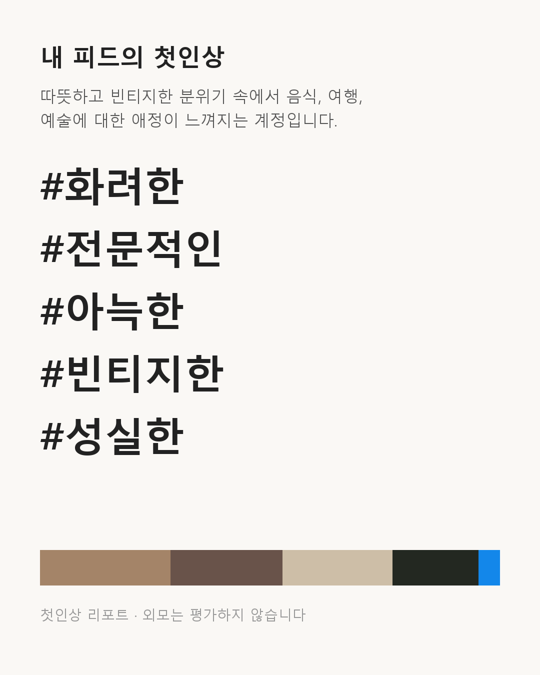

In [13]:
def to_markdown(report, color, clip, tone, issues):
    by_id = {c["id"]: c for c in GUIDE_CARDS}
    lines = [f"### 첫인상 한 줄\n> {report['summary']}\n", "### 첫인상 키워드 5"]
    for i, k in enumerate(report["keywords"], 1):
        lines.append(f"{i}. **{k['word']}**: {k['reason']} *(사진 {', '.join(map(str, k['photos']))})*")
    lines += ["", "### 피드 분석",
              f"- 대표색: {' '.join(h for h, _ in color['palette'])}",
              f"- 밝기 {color['brightness']} · 채도 {color['saturation']} · 통일감 {color['unity']} "
              f"({', '.join(color['labels']) or '보통'}) · 튀는 사진 {color['outlier_photo']}번",
              f"- 주제: {', '.join(f'{t} {n}장' for t, n in clip['topics'].items())}",
              f"- 소개글 톤: {tone['label']} (직무 키워드 {'있음' if tone['job_keyword'] else '없음'}, "
              f"링크 {'있음' if tone['link'] else '없음'}, 이모지 {tone['emoji']}개)",
              "", "### 개선안 3"]
    for s in report["suggestions"]:
        lines.append(f"- **[{s['area']}]** {s['action']}  \n  왜: {s['why']}  \n"
                     f"  근거 카드: {s['source']} {by_id[s['source']]['title']}")
    lines += ["", "---", f"외모는 평가하지 않습니다. · 검증 단계 수정 {len(issues)}건"]
    return "\n".join(lines)


def keyword_card(report, color, path):
    W, H = 1080, 1350
    img = Image.new("RGB", (W, H), "#faf8f5")
    d = ImageDraw.Draw(img)
    font = lambda size, bold=False: ImageFont.truetype(
        "C:/Windows/Fonts/malgunbd.ttf" if bold else "C:/Windows/Fonts/malgun.ttf", size)
    d.text((80, 80), "내 피드의 첫인상", font=font(48, True), fill="#222")
    y = 170
    first = re.split(r"(?<=[.!?다])\s", report["summary"].strip())[0]    # 카드에는 첫 문장만
    lines = textwrap.wrap(first, 26)
    if len(lines) > 3:
        lines = lines[:3]
        lines[-1] = lines[-1][:24] + "…"
    for line in lines:
        d.text((80, y), line, font=font(32), fill="#555")
        y += 48
    y += 50
    for k in report["keywords"]:
        d.text((80, y), f"#{k['word']}", font=font(80, True), fill="#222")
        y += 125
    x, top = 80, H - 250
    for hexc, share in color["palette"]:
        w = round((W - 160) * share)
        d.rectangle((x, top, x + w, top + 70), fill=hexc)
        x += w
    d.text((80, H - 140), "첫인상 리포트 · 외모는 평가하지 않습니다", font=font(28), fill="#999")
    img.save(path)
    return img


display(Markdown(to_markdown(report, color, clip, tone, issues)))

card_img = keyword_card(report, color, OUT_DIR / "keyword_card.png")
with open(OUT_DIR / "report.json", "w", encoding="utf-8") as f:
    json.dump({"report": report, "issues": issues, "color": {k: v for k, v in color.items()},
               "clip_top5": clip["top5"], "topics": clip["topics"], "tone": tone,
               "captions": captions, "cards": [c["id"] for c in cards]}, f, ensure_ascii=False, indent=1)
print("저장:", OUT_DIR / "keyword_card.png", "/", OUT_DIR / "report.json")
display(card_img.resize((540, 675)))

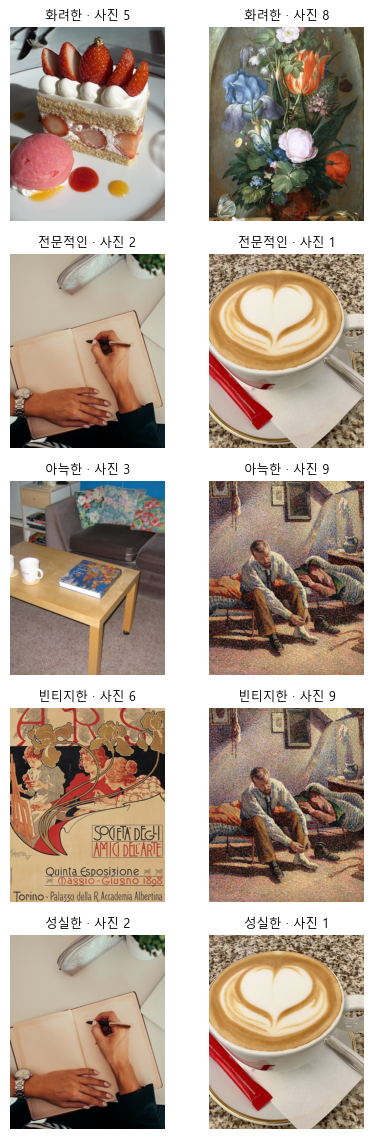

In [14]:
# 근거 사진 확인: 키워드마다 CLIP이 고른 사진 2장
fig, axes = plt.subplots(len(report["keywords"]), 2, figsize=(4.5, 2.3 * len(report["keywords"])))
for r, k in enumerate(report["keywords"]):
    for c, p in enumerate(k["photos"][:2]):
        axes[r, c].imshow(images[p - 1]); axes[r, c].set_title(f"{k['word']} · 사진 {p}", fontsize=9)
    for c in range(2):
        axes[r, c].axis("off")
plt.tight_layout(); plt.show()

## [G] 목표 인상: 사진 순서 제안 (확장)
원하는 인상(`TARGET`)을 고르면, [B]에서 구한 사진별 점수로 9장을 줄 세워 첫 줄에 올릴 사진과 아래로 내릴 사진을 제안한다. 모델을 다시 돌리지 않는다.

목표 인상 '전문적인'에 가까운 순서: [2, 1, 7, 3, 9, 5, 4, 6, 8]
→ 첫 줄 추천: 사진 [2, 1, 7] / 아래로 내릴 사진: [4, 6, 8]
현재 계정 점수 0.0785 (30개 중 2위)


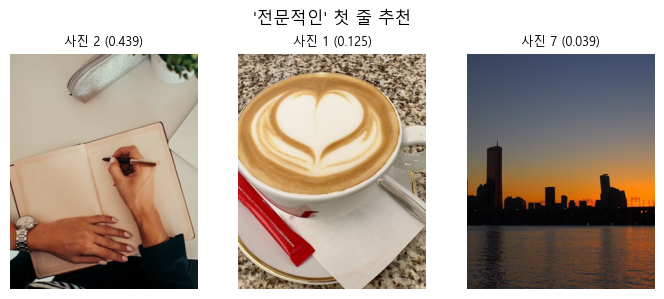

In [15]:
t = next(i for i, k in enumerate(KEYWORDS) if k["ko"] == TARGET)
target_scores = np.array(clip["per_photo"])[:, t]
rank = [int(i) + 1 for i in np.argsort(-target_scores)]
print(f"목표 인상 '{TARGET}'에 가까운 순서: {rank}")
print(f"→ 첫 줄 추천: 사진 {rank[:3]} / 아래로 내릴 사진: {rank[-3:]}")
print(f"현재 계정 점수 {scores[t]:.4f} (30개 중 {int((scores > scores[t]).sum()) + 1}위)")

fig, axes = plt.subplots(1, 3, figsize=(7, 3))
for ax, p in zip(axes, rank[:3]):
    ax.imshow(images[p - 1]); ax.set_title(f"사진 {p} ({target_scores[p - 1]:.3f})", fontsize=9); ax.axis("off")
plt.suptitle(f"'{TARGET}' 첫 줄 추천"); plt.tight_layout(); plt.show()

## 정리
- 다른 사진으로 다시 돌리려면 `samples/`의 사진과 설정 셀의 `BIO`를 바꾸고 처음부터 실행한다.
- 다음 단계: 평가용 계정 10~15개와 설문 응답을 모아 키워드 일치도(Precision@5, Spearman)와 어블레이션(CLIP만 / 캡션 → EXAONE / 전체)을 잰다. 가이드 카드는 출처를 붙여 40장 안팎으로 늘린다.

In [16]:
# 모델 내리기
del llm, clip_model
free_gpu()

GPU 사용량: 0.01 GB
